# A PROJECT TO ANALYSE AND BUILD MODELS TO PREDICT THE HABITUAL CHANGE OF THE MENTALLY CHALLENGED INDIVIDUALS
   ## Project Overview
   ###  Problem Statement
- **Numerous cases of mental health challenges** have been encountered across various countries in the world.
   Due to various circumstances circulating people across the the world. 
- Extreme cases of mental health challenges *leads to abnormal functioning of human being causing madness and 
   sometimes causes death in severe cases.*

  ### Aim of Project
- Analysing circumstances surrounding people across various regions of the world under which some victim people 
   contract mental health infections.
- Building up insights ,creating and employing the appropriate criterias to curb various mental-health-causing 
   circumstances circulating people's lives.
- Creating Various activities involving many people together to bring people from their various day activities for 
   consultation and creating awareness.

  ### Data Understanding
- The mental health dataset is from [kaggle](https://www.kaggle.com/datasets/bhavikjikadara/mental-health-dataset)
- It has got *sixteen columns*
- **Gender** - indication of either a patient is Male or Female
- **Country** - a nation to the patient belongs to
- **Occupation** - the job the patinet was doing
- **SelfEmployed** - an indication whether a patient was self-employed (Yes/No) or not sure
- **FamilyHistory** - A trace mental health challenge in the patient's family (Yes/No) or not sure 
- **Treatment** - confirming whether the patient received Treatment (Yes/No) or not sure
- **DaysIndoors** - number of days the patient stayed locked in given premises
- **HabitsChange** -an indication if there was change in behavior of the patient (Yes/No) or not sure
- **MentalHealthHistory** - previous traces of mental health challenges(Yes/No) or not sure
- **IncreasingStress** - rise in stress levels (Yes/No) or not sure
- **MoodSwings** - refers to shift of the mood (High/Medium/low)
- **SocialWeakness** - shortcomings in terms of social life(Yes/No) or not sure
- **CopingStruggles** - improvements witnessed (Yes/No) 
- **WorkInterest** - patient building up a working interest (Yes/Not) or not sure
- **MentalHealthInterview** - record of if ever had a mental health interview (Yes/No) or not sure
- **CareOptions** - care options the patient (Yes/No) or not sure


  ### The flow of the project
1. **Data cleaning** 
- removing duplicate columns
- dropping duplicates
- filling empty cells
2. **feature engineering**
3. **data visualization**
4. **Modelling using supervised machine learning**
5. **Valuation Metrics**
6. **Conclusions**
7. **Recommendations**


In [47]:
import pandas as pd
import numpy as np

In [48]:
fd=pd.read_csv("Mental Health dataset1.csv")

In [49]:
fd.head()

,Gender,Country,Occupation,SelfEmployed,FamilyHistory,Treatment,DaysIndoors,HabitsChange,MentalHealthHistory,IncreasingStress,MoodSwings,SocialWeakness,CopingStruggles,WorkInterest,SocialWeakness.1,MentalHealthInterview,CareOptions
0,Female,UK,Others,No,Yes,No,15-30 days,No,Yes,Yes,High,No,Yes,Maybe,No,No,No
1,Female,USA,Housewife,No,Yes,No,15-30 days,Maybe,Maybe,Yes,High,Maybe,Yes,Maybe,Maybe,No,Not sure
2,Female,Canada,Others,No,No,Yes,More than 2 months,Maybe,No,No,Medium,No,No,No,No,No,Not sure
3,Female,Canada,Corporate,No,Yes,Yes,Go out Every day,No,Maybe,No,Medium,No,No,Maybe,No,No,Not sure
4,Female,UK,Corporate,No,No,Yes,More than 2 months,Yes,No,Maybe,Medium,Maybe,No,Maybe,Maybe,No,Not sure


In [50]:
print(fd.columns.tolist())

['Gender', 'Country', 'Occupation', 'SelfEmployed', 'FamilyHistory', 'Treatment', 'DaysIndoors', 'HabitsChange', 'MentalHealthHistory', 'IncreasingStress', 'MoodSwings', 'SocialWeakness', 'CopingStruggles', 'WorkInterest', 'SocialWeakness.1', 'MentalHealthInterview', 'CareOptions']


## Data Cleaning

In [51]:
print(fd["SocialWeakness"] == fd["SocialWeakness.1"])

0         True
1         True
2         True
3         True
4         True
          ... 
261323    True
261324    True
261325    True
261326    True
261327    True
Length: 261328, dtype: bool


In [52]:
fd=fd.drop(columns=["SocialWeakness.1"])

In [53]:
fd.isnull().sum()

Gender                      0
Country                     0
Occupation                  0
SelfEmployed             4356
FamilyHistory               0
Treatment                   0
DaysIndoors                 0
HabitsChange                0
MentalHealthHistory         0
IncreasingStress            0
MoodSwings                  0
SocialWeakness              0
CopingStruggles             0
WorkInterest                0
MentalHealthInterview       0
CareOptions                 0
dtype: int64

In [54]:
fd["SelfEmployed"]=fd["SelfEmployed"].bfill()

In [55]:
fd.duplicated().sum()

np.int64(178142)

In [56]:
fd=fd.drop_duplicates()

## Exploratory Data Analysis(EDA)

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

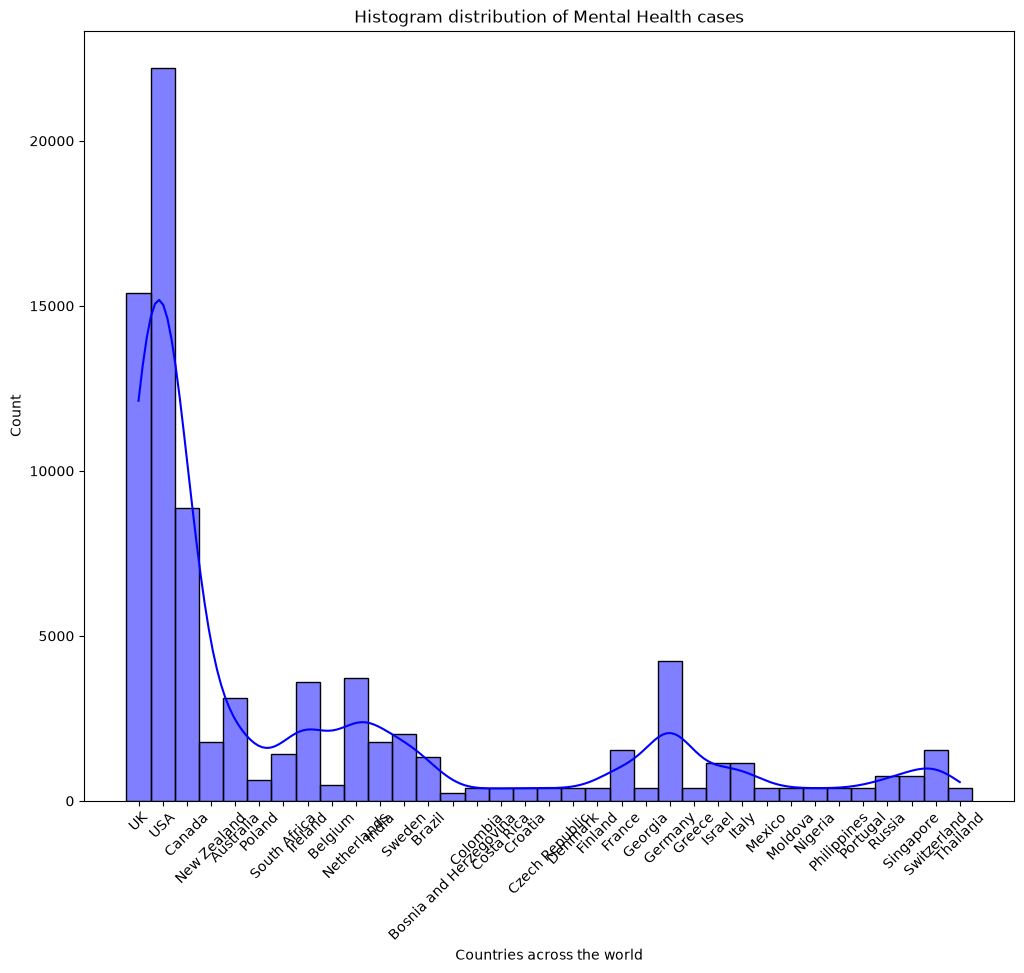

In [58]:
#plotting a histogram
plt.figure(figsize=(12,10))
sns.histplot(x="Country",color="blue",kde=True,data=fd)
plt.title("Histogram distribution of Mental Health cases")
plt.xlabel("Countries across the world")
plt.xticks(rotation=45)
plt.xticks(rotation=45)
plt.show()

- USA holds at first,followed by UK,then Canada having the highest count of cases with the mental health challenges across the sammpled countries across the world.
- Brazil has the lowest count of cases on mental health challenges across the sampled world countries.This means there are factor variations
attributed to the difference between the count in the USA and Brazil.

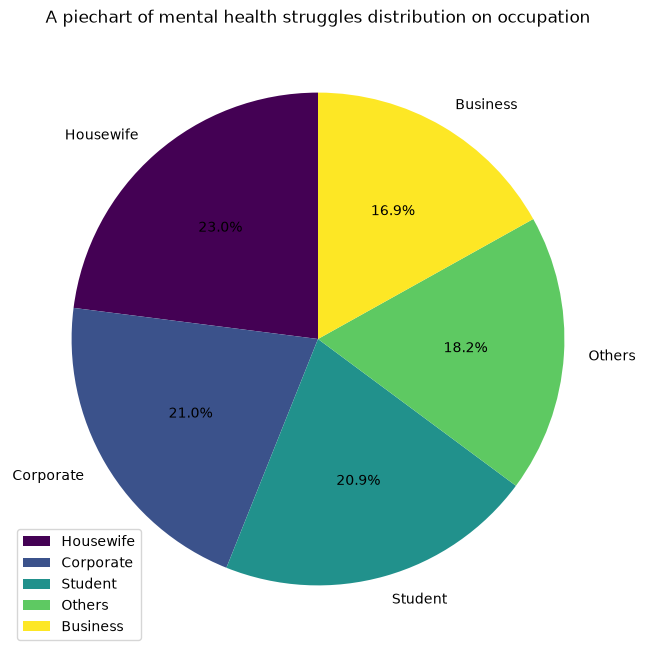

In [59]:
#plotting a piechart
plt.figure(figsize=(8,8))
case=fd["Occupation"].value_counts()
case.plot(kind="pie",autopct="%1.1f%%",startangle=90,cmap="viridis")
plt.title("A piechart of mental health struggles distribution on occupation")
plt.legend()
plt.show()

- People involved in Business as an occupation experience lowest case count of mental health challenges as compared to the other occupations.
- on the other hand  people involved Housewife occupations experience the highest case count of the mental health challenges.

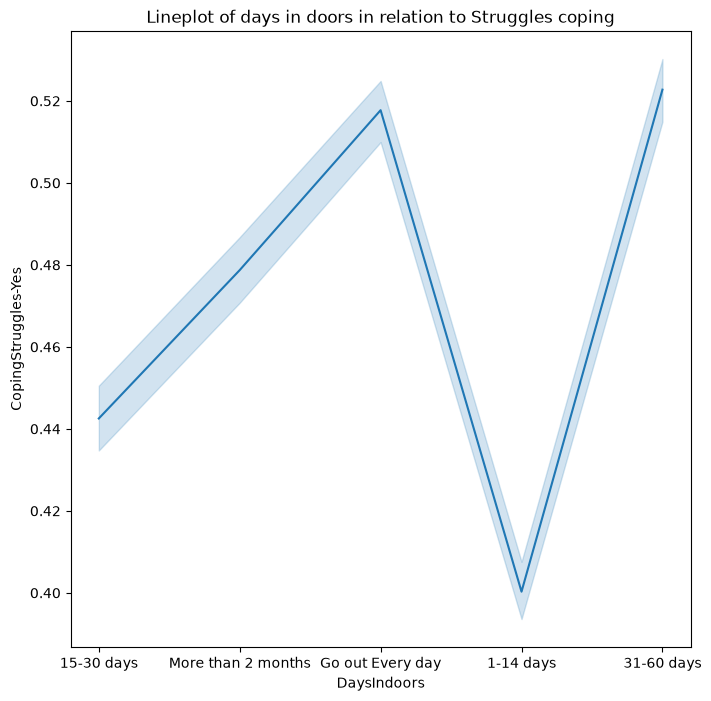

In [60]:
fd["CopingStruggles_Yes"]=(fd["CopingStruggles"]=="Yes").astype(int)
fd[["CopingStruggles","CopingStruggles_Yes"]].head()
#plottig a lineplot
plt.figure(figsize=(8,8))
sns.lineplot(x="DaysIndoors",y="CopingStruggles_Yes",data=fd)
plt.title("Lineplot of days in doors in relation to Struggles coping")
plt.xlabel("DaysIndoors")
plt.ylabel("CopingStruggles-Yes")
plt.show()

- As a factor to consider, people going out every day after Treatment experience a higher count in coping with their mental health struggles
- people staying lesser days (1 - 14 days) Indoors experience a lower count in coping with their mental health struggles.It's be of greater concern by the psychiatrists

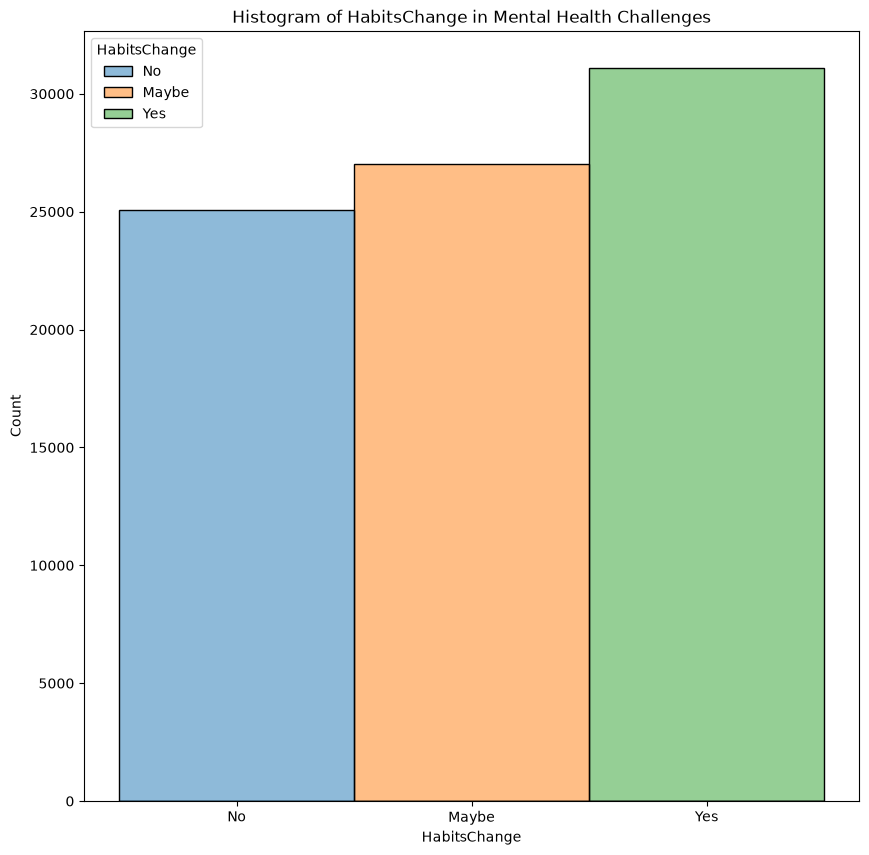

In [61]:
plt.figure(figsize=(10,10))
sns.histplot(x="HabitsChange",alpha=0.5,hue="HabitsChange",edgecolor="black",data=fd)
plt.xlabel("HabitsChange")
plt.ylabel("Count")
plt.title("Histogram of HabitsChange in Mental Health Challenges")
plt.show()

- Of the sampled population ,the highest number of mentally challenged people experience habits change,followed by those whose conditions are uncertain while the least do not experience habitschange.
- unusual behavoural changes as a sign of mental illness may occur or may not occur ,any other sign of the illness should give a precaution for  the treatment.

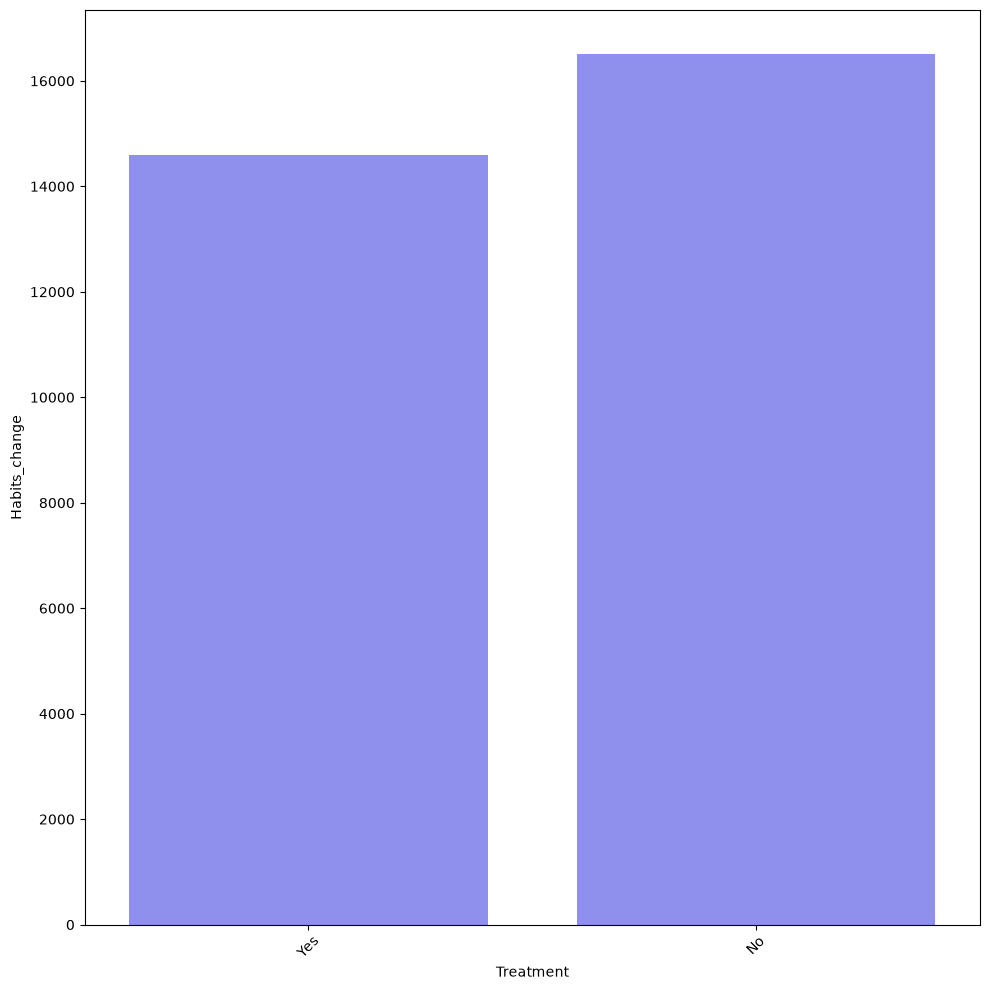

In [62]:
hbc=fd[fd["HabitsChange"]=="Yes"]
plt.figure(figsize=(10,10))
sns.countplot(data=hbc,x="Treatment",color="blue",alpha=0.5)
plt.xlabel("Treatment")
plt.ylabel("Habits_change")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


- people undergoing mental health Treatment have a lesser count in the habits change on mental health challenge.
- people failing to take mental health treatment have a higher count in the habits change on mental health challenge.

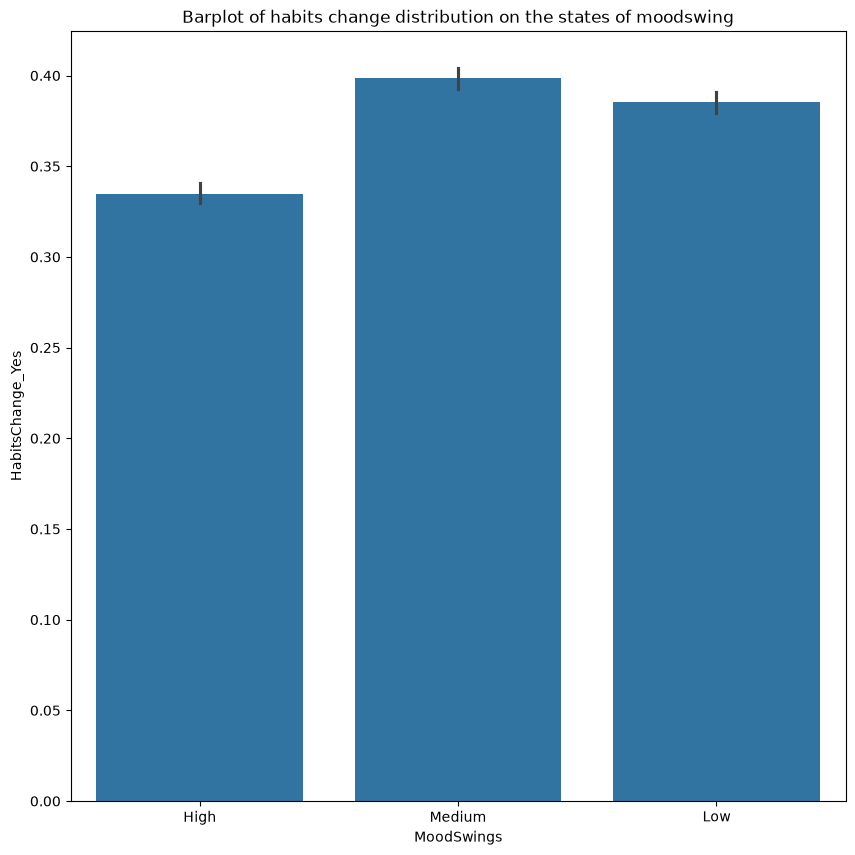

In [63]:
#plotting a barplot
fd["HabitsChange_Yes"]=(fd["HabitsChange"]=="Yes").astype(int)
fd[["HabitsChange","HabitsChange_Yes"]].head()
plt.figure(figsize=(10,10))
sns.barplot(x="MoodSwings",y="HabitsChange_Yes",data=fd)
plt.title("Barplot of habits change distribution on the states of moodswing")
plt.show()

- Medium moodswing,followed by Low moodswing experience largest count in the habits change on mental health struggles.
- High moodswing exprience the smallest count in habits change on mental health struggles.

In [64]:
from sklearn.preprocessing import LabelEncoder
#selecting relevant columns
use_columns=["Gender","Country","Occupation","SelfEmployed","FamilyHistory","Treatment","DaysIndoors","HabitsChange","MentalHealthHistory","IncreasingStress","MoodSwings","SocialWeakness","CopingStruggles","WorkInterest","MentalHealthInterview","CareOptions"]
#copying sected columns
data=fd[use_columns].copy()
#encoding selected categorical data
label_encoders={}
for col in data.select_dtypes(include=["object","category","string"]):
    encoder=LabelEncoder()
    data[col]=encoder.fit_transform(data[col])
    label_encoders[col]=encoder
#convert Boolean columns to int
for col in data.select_dtypes(include=["bool"]).columns:
    data[col]=data[col].astype(int)


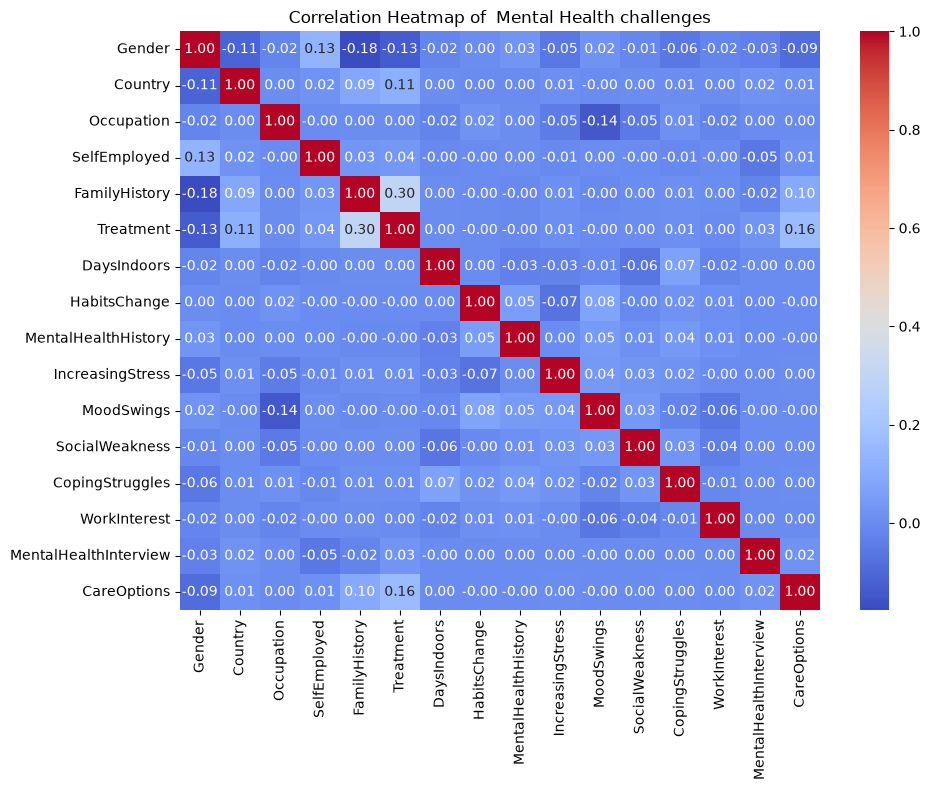

In [65]:
plt.figure(figsize=(10, 8))
#calculating correlation
correlation_matrix=data.corr(method="pearson")
#plotting heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of  Mental Health challenges")
plt.tight_layout()
plt.show()

- FamilyHistory in mental health concerns is weakly correlated to the Treatment ,which can
 be used to somehow to predict whether the patient requires treatment or not.
- Treatment is weakly correlated to the careoptons in the mental health challenges

## Conclusions
- Most individuals under mental health struggles allowed move out every, cope with their mental struggles.
- Of the recorded occupations ,Housewife indulging people have the highest count in the mental health records.
- FamilyHistory on mental health struggles is moderately weakly correlated to the treatment thus can be used to predict whether the patient needs treatment or not depending on the instance.
## Recommendations
- Psychiatrists should employ "every day out" to the capable group of mental health patients to cope with their struggles.
- Housewives should be handled by their employers considerably on balancing their own families affairs and work affairs.
- The correspondence of Family History and the treatment of the mental health challenge should be taken keenly as far as coping with it's struggles is of concern.

## Habitual change predicting modelling in mental illness

In [66]:
#importing the necessary libraries
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report

In [67]:
#dropping the target
X=fd.drop(columns=["HabitsChange"])
y=fd["HabitsChange"]
#encoding string values to numeric
X_encoded=pd.get_dummies(X,drop_first=True)
y_encoded=y.map({"Yes":2,"No":1,"maybe":0})
le=LabelEncoder()
y_encoded=le.fit_transform(y)

In [68]:
y.unique()

<StringArray>
['No', 'Maybe', 'Yes']
Length: 3, dtype: str

In [69]:
#train_test_split
X_train,X_test,y_train,y_test=train_test_split(X_encoded,y_encoded,test_size=0.2,random_state=42)

### Logistic Regression

In [70]:
#instanstiating the model
lr=LogisticRegression(max_iter=1000,random_state=42)


In [71]:
dup_cols=X_train.columns[X_train.columns.duplicated()]
print(dup_cols)

Index(['CopingStruggles_Yes'], dtype='str')


In [72]:
#removing duplicate columns from the trained data
X_train=X_train.loc[:,~X_train.columns.duplicated()]
X_test=X_test.loc[:,~X_test.columns.duplicated()]

In [73]:
#fit the trained model
lr.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [74]:
#predict
y_pred_lr=lr.predict(X_test)

In [75]:
#evaluation metrics
print("  Logistic Regression")
print("Acuracy  :",accuracy_score(y_test,y_pred_lr))
print("Precision:",precision_score(y_test,y_pred_lr,average="weighted"))
print("F1score  :",f1_score(y_test,y_pred_lr,average="weighted"))
print("Recall   :",recall_score(y_test,y_pred_lr,average="weighted"))
print("Classification_report:",classification_report(y_test,y_pred_lr))

  Logistic Regression
Acuracy  : 0.7630123812958288
Precision: 0.7635486582791282
F1score  : 0.7612925032434348
Recall   : 0.7630123812958288
Classification_report:               precision    recall  f1-score   support

           0       0.62      0.70      0.66      5418
           1       0.63      0.54      0.58      5089
           2       1.00      1.00      1.00      6131

    accuracy                           0.76     16638
   macro avg       0.75      0.75      0.75     16638
weighted avg       0.76      0.76      0.76     16638



### multinomial logistic regresion
- The accuracy of the model is around 76%  and this could be a limitation by 24% to reliability of it.This is a risk to the wrong quarter of the total predictions.

### RandomForest

In [76]:
from sklearn.ensemble import RandomForestClassifier
# instanstiating the model
model=RandomForestClassifier(n_estimators=200,random_state=42,max_depth=5,class_weight="balanced")



In [77]:
#fit the trained model
model.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 T

In [78]:
#predict
y_pred_rf=model.predict(X_test)

In [79]:
#evaluation metrics
print("   RandomForest Clasification")
print("Accuracy :",accuracy_score(y_test,y_pred_rf))
print("Precision:",precision_score(y_test,y_pred_rf,average="weighted"))
print("F1score  :",f1_score(y_test,y_pred_rf,average="weighted"))
print("Recall   :",recall_score(y_test,y_pred_rf,average="weighted"))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred_rf))

   RandomForest Clasification
Accuracy : 0.8510037264094242
Precision: 0.8514271022235359
F1score  : 0.8506858227284917
Recall   : 0.8510037264094242
Confusion Matrix: [[4352 1066    0]
 [1413 3676    0]
 [   0    0 6131]]


- For the Randomforest model, the accuracy of the model is about 85% which can be more reliable to predicting the change in habits as compared to logistic regression

Text(0.5, 1.0, 'Confusion matrix RandomForest')

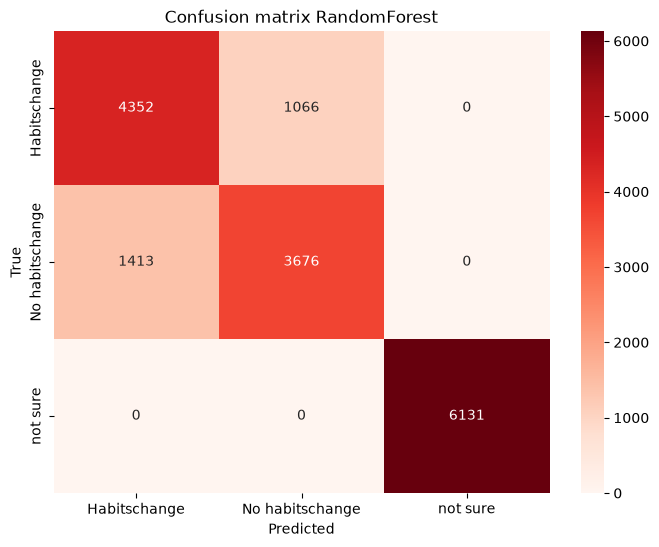

In [80]:
#plottig the confusion matrix
cm_forest=confusion_matrix(y_test,y_pred_rf)
labels=["Habitschange","No habitschange","not sure"]
plt.figure(figsize=(8,6))
sns.heatmap(cm_forest,annot=True,fmt="d",cmap="Reds",xticklabels=labels,yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix RandomForest")

- correct predictions for habitschange is 4352 while those correctly for no habitschange is 3676 as the model does not confuse the 'maybe' with habitschange (Yes\No) predictions

## Gradient Boosting

In [81]:
# importing the gradient boost
from sklearn.ensemble import GradientBoostingClassifier

In [82]:
#instanstiating the model
gb=GradientBoostingClassifier(random_state=42)



In [83]:
#fitting
gb.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [84]:
#predict
y_pred_gb=gb.predict(X_test)

In [85]:
print("Accuracy             :", accuracy_score(y_test, y_pred_gb))
print("Precision            :",precision_score(y_test,y_pred_gb,average="weighted"))
print("F1score              :",f1_score(y_test,y_pred_gb,average="weighted"))
print("Recall               :",recall_score(y_test,y_pred_gb,average="weighted"))
print("Confusion Matrix     :",confusion_matrix(y_test,y_pred_gb))
print("Classification_report:",classification_report(y_test,y_pred_gb))

Accuracy             : 0.8583964418800336
Precision            : 0.8600363644126707
F1score              : 0.8577228113464445
Recall               : 0.8583964418800336
Confusion Matrix     : [[4528  890    0]
 [1466 3623    0]
 [   0    0 6131]]
Classification_report:               precision    recall  f1-score   support

           0       0.76      0.84      0.79      5418
           1       0.80      0.71      0.75      5089
           2       1.00      1.00      1.00      6131

    accuracy                           0.86     16638
   macro avg       0.85      0.85      0.85     16638
weighted avg       0.86      0.86      0.86     16638



- the overall reliability of the Gradientboosting is around 85% ,so it's a better model to use.
- precision for the 'No' class is 80% which is the correct predictions for the class.
- 84% recall for 'Yes' class gives the correctly identified of the total samples that belonged to the class.


## Comparison of the Models

In [86]:
#comparing classifying models
results =pd.DataFrame({"Model":["Logistic Regression","Random Forest","Gradient Boosting"],
                       "Accuracy":[accuracy_score(y_test,y_pred_lr),

                        accuracy_score(y_test,y_pred_rf),
      
                        accuracy_score(y_test,y_pred_gb)
                          ],
                     "Precision":
                           [precision_score(y_test,y_pred_lr,average="weighted"),

                            precision_score(y_test,y_pred_rf,average="weighted"),
                            
                            precision_score(y_test,y_pred_gb,average="weighted")
                            ],
                            "Recall":[recall_score(y_test,y_pred_lr,average="weighted"),
                                      recall_score(y_test,y_pred_rf,average="weighted"),
                                  
                                      recall_score(y_test,y_pred_gb,average="weighted")
                                      ],
                            "F1 score":[f1_score(y_test,y_pred_lr,average="weighted"),
                                        f1_score(y_test,y_pred_rf,average="weighted"),
                                      
                                        f1_score(y_test,y_pred_gb,average="weighted")],          
})
print(results)

                 Model  Accuracy  Precision    Recall  F1 score
0  Logistic Regression  0.763012   0.763549  0.763012  0.761293
1        Random Forest  0.851004   0.851427  0.851004  0.850686
2    Gradient Boosting  0.858396   0.860036  0.858396  0.857723


In [9]:
# Collaborative filtering on the FULL dataset (all ~261k rows)
# ============================================================
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import f1_score

# ---- 1. Reload the raw data, clean it, but do NOT drop duplicates -----
df = pd.read_csv("Mental Health dataset1.csv")
df = df.drop(columns=["SocialWeakness.1"], errors="ignore")
df["SelfEmployed"] = df["SelfEmployed"].bfill().fillna("No")

target = "CareOptions"
feature_cols = [c for c in df.columns if c != target]
print("Rows used:", len(df))

# ---- 2. Split rows 80/20 ----------------------------------------------
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df[target]
)

# ---- 3. Collapse train into unique profiles + CareOptions counts ------
counts = (train_df.groupby(feature_cols + [target]).size()
                  .unstack(fill_value=0))
classes = counts.columns.to_numpy()                      # e.g. ['No','Not sure','Yes']
C = counts.values.astype(np.float32)                     # (n_profiles, n_classes)
profiles = counts.index.to_frame(index=False)

P = pd.get_dummies(profiles).astype(np.float32)
feat_cols = P.columns
P_norm = normalize(P.values)                             # unit vectors -> dot product = cosine
prior = C.sum(0) / C.sum()                               # class shares in training

print(f"Unique training profiles: {len(profiles)}  |  classes: {list(classes)}")

def encode(frame):
    X = (pd.get_dummies(frame[feature_cols])
           .reindex(columns=feat_cols, fill_value=0).astype(np.float32))
    return normalize(X.values)

# ---- 4. Recommend for a single new patient ----------------------------
def recommend_care_option(profile, k=300, power=4, alpha=0.0):
    x = encode(pd.DataFrame([profile]))
    sims = (x @ P_norm.T)[0]
    top = np.argpartition(-sims, k)[:k]
    w = sims[top] ** power
    scores = (w[:, None] * C[top]).sum(0) / (prior ** alpha)
    scores = pd.Series(scores / scores.sum(), index=classes).sort_values(ascending=False)
    return scores.index[0], scores

new_patient = {
    "Gender": "Female", "Country": "UK", "Occupation": "Housewife",
    "SelfEmployed": "No", "FamilyHistory": "Yes", "Treatment": "No",
    "DaysIndoors": "15-30 days", "HabitsChange": "Yes",
    "MentalHealthHistory": "Yes", "IncreasingStress": "Yes",
    "MoodSwings": "High", "SocialWeakness": "Maybe",
    "CopingStruggles": "Yes", "WorkInterest": "Maybe",
    "MentalHealthInterview": "No",
}
best, scores = recommend_care_option(new_patient)
print("\nRecommended CareOption:", best)
print(scores.round(3))

# ---- 5. Evaluation: find neighbours once, then test many settings -----
n_eval, kmax, batch = 3000, 1000, 250
ev = test_df.sample(n_eval, random_state=42).reset_index(drop=True)
y_true = ev[target].values
T_norm = encode(ev)

idx_all, sim_all = [], []
for s in range(0, n_eval, batch):
    sims = T_norm[s:s + batch] @ P_norm.T
    part = np.argpartition(-sims, kmax, axis=1)[:, :kmax]
    ps = np.take_along_axis(sims, part, 1)
    order = np.argsort(-ps, axis=1)
    idx_all.append(np.take_along_axis(part, order, 1))
    sim_all.append(np.take_along_axis(ps, order, 1))
idx_all, sim_all = np.vstack(idx_all), np.vstack(sim_all)

def predict(k, power, alpha):
    w = sim_all[:, :k] ** power
    sc = np.einsum("bk,bkc->bc", w, C[idx_all[:, :k]]) / (prior ** alpha)
    return classes[sc.argmax(1)]

# "unseen" = test patients whose exact answers never appear in training
train_keys = set(map(tuple, profiles.values))
unseen = np.array([tuple(r) not in train_keys for r in ev[feature_cols].values])

baseline = (y_true == classes[prior.argmax()]).mean()
print(f"\nMajority-class baseline: {baseline:.3f}   |   unseen-profile share: {unseen.mean():.1%}")

rows = []
for k in [50, 100, 300, 500, 1000]:
    for power in [1, 4, 8]:
        for alpha in [0.0, 0.5, 1.0]:
            p = predict(k, power, alpha)
            rows.append(dict(k=k, power=power, alpha=alpha,
                             accuracy=(p == y_true).mean(),
                             macro_f1=f1_score(y_true, p, average="macro"),
                             acc_unseen=(p[unseen] == y_true[unseen]).mean() if unseen.any() else np.nan))
results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
print(results.head(10).round(3).to_string(index=False))

Rows used: 261328
Unique training profiles: 49862  |  classes: ['No', 'Not sure', 'Yes']

Recommended CareOption: No
No          0.449
Not sure    0.293
Yes         0.258
dtype: float32

Majority-class baseline: 0.420   |   unseen-profile share: 14.3%
   k  power  alpha  accuracy  macro_f1  acc_unseen
 100      1    1.0     0.498     0.493       0.536
 100      4    1.0     0.491     0.486       0.513
 300      1    1.0     0.492     0.486       0.534
 300      4    1.0     0.489     0.483       0.524
 500      4    1.0     0.486     0.480       0.520
 500      1    1.0     0.486     0.480       0.503
 500      8    1.0     0.483     0.477       0.513
 300      8    1.0     0.483     0.477       0.513
 100      8    1.0     0.481     0.475       0.480
1000      8    1.0     0.478     0.472       0.492


## Conclusions
- The reliability of the Gradientboosting model is around 85% which is relatively a higher probability to the predict change in habits of the mental illness.
- Based on the confusion matrix plot for the randomforest ,the model never confuses the uncertainty of change in habits with the (Yes\No) predictions.
- The model used progressively improve their performance as revealed by accuracy and the classificaztion report.
## Recommendations
- The best model to use is the Gradient boosting considering it's overall performance despite the slight difference with randomforest.
- The predictions of change in habits  by the well performing model would really help in recommending treatment, as concern in the visuals;those who undergo treatment have a lesser count in habits change.